# EDA: King County Housing — Client William Rodriguez

**Client:** William Rodriguez, buyer, household of 2. Wants **two** homes:
1. A **country** home — best possible timing to buy, and open to (actually prefers) **non-renovated** stock.
2. A **city** home — needs to move **fast**, wants a **central** location.

## Working assumptions

- **"Country"** = zip codes with larger median lot sizes and greater distance from the Seattle urban core (low density, more land).
- **"City"** = zip codes closest to downtown Seattle with smaller lots / higher density.
- **"Best timing"** (country home) = the month(s) in the 2014-05 to 2015-05 sales window with the lowest median price and/or highest inventory — a buyer's-market window.
- **"Non-renovated"** = `yr_renovated == 0` (per `column_names.md`, 0/NaN indicates no renovation on record).
- **"Fast"** (city home) = prioritize zip codes with the highest sales turnover (transaction volume), since more turnover means more listings cycling through and a shorter realistic search.
- **"2 people"** = no bedroom minimum required; used only as a soft signal against oversized/overpriced homes.
- `house_id` / `sale_id` are identifier columns — dropped from analysis, not treated as features.
- This dataset is almost entirely numeric. The categorical-vs-quantitative section uses `zipcode`, `condition`, `grade`, `waterfront`, `view`, and the `is_city`/`is_country` flags built during segmentation as categorical stand-ins.


## Research questions & hypotheses

3 questions (one geographic) for William Rodriguez's two-house search.

| # | Question | Hypothesis | Indicators |
|---|---|---|---|
| 1 (geo) | Where are King County's "city" (central, high-turnover) vs "country" (low-density) zip codes, and how do price and price-per-sqft differ between them? | Homes closer to downtown Seattle carry a price-per-sqft premium and cluster in high-turnover zip codes; outlying zip codes have larger lots at a lower price-per-sqft. | `lat`/`long` distance to downtown, `zipcode` sales counts, `sqft_lot`, `price_per_sqft`, `is_city`/`is_country` |
| 2 | Among "country" homes specifically, does renovation status affect price? | Non-renovated country homes sell for less than renovated ones of similar standing — good news for a buyer open to non-renovated stock. | `is_country`, `yr_renovated`, `price` |
| 3 | Is there a seasonal pattern in price or sales volume that points to a "best time to buy"? | Median price and/or sales volume dip in certain months, giving a buyer's-market window for timing the country home purchase. | `date` → month, median `price`, monthly transaction counts |

---

Dependency management , open a terminal in your project root and run:

`uv sync`

---

Add this cell at the top of the notebook and run it to tell which Python the notebook is actually using.

In [131]:
import sys
print(sys.executable)
print(sys.version)

/Users/jolenndarensbourg/code/jolennd/bootcamp/neueFische/projects/ds-eda-project/.venv/bin/python
3.13.14 (main, Jun 23 2026, 15:20:43) [Clang 22.1.3 ]


---

## Preparations
Import the libraries and load the joined dataset.

In [132]:
import operator
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

plt.rcParams.update(
    {"figure.figsize": (8, 5), "axes.facecolor": "white", "axes.edgecolor": "black"}
)
plt.rcParams["figure.facecolor"] = "w"
pd.plotting.register_matplotlib_converters()
pd.set_option("display.float_format", lambda x: "%.3f" % x)

---

## Data

Data comes from `eda` schema, two tables: `king_county_house_sales` (one row per transaction: `date`, `price`, `house_id`) and `king_county_house_details` (one row per property, keyed by `id`).

**Join:** every `house_id` in `sales` matches exactly one `id` in `details` (no orphans either direction).

176 properties were sold more than once in the window, so `sales` is the grain-defining ("many") side.

```sql
SELECT *
FROM eda.king_county_house_sales AS sales
JOIN eda.king_county_house_details AS details
  ON sales.house_id = details.id
```

Run that in `03_fetching_the_data_eda.ipynb`, export to `data/eda.csv`, then load it here.

---

## Load data

Load the joined sales + property-details dataset produced by 03_fetching_the_data_eda.ipynb, then convert the date column from plain text to a real pandas datetime type so it can be sorted, filtered, and grouped by month/year later in the notebook.

In [133]:
# load joined sales + property-details dataset produced by 03_fetching_the_data_eda.ipynb
df = pd.read_csv("data/eda.csv")
df["date"] = pd.to_datetime(df["date"])
df.head()

,date,price,house_id,sale_id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,2014-10-13,221900.000,7129300520,1,3.000,1.000,1180.000,5650.000,1.000,NaN,...,7,1180.000,0.000,1955,0.000,98178,47.511,-122.257,1340.000,5650.000
1,2014-12-09,538000.000,6414100192,2,3.000,2.250,2570.000,7242.000,2.000,0.000,...,7,2170.000,400.000,1951,19910.000,98125,47.721,-122.319,1690.000,7639.000
2,2015-02-25,180000.000,5631500400,3,2.000,1.000,770.000,10000.000,1.000,0.000,...,6,770.000,0.000,1933,NaN,98028,47.738,-122.233,2720.000,8062.000
3,2014-12-09,604000.000,2487200875,4,4.000,3.000,1960.000,5000.000,1.000,0.000,...,7,1050.000,910.000,1965,0.000,98136,47.521,-122.393,1360.000,5000.000
4,2015-02-18,510000.000,1954400510,5,3.000,2.000,1680.000,8080.000,1.000,0.000,...,8,1680.000,0.000,1987,0.000,98074,47.617,-122.045,1800.000,7503.000


---

Print the earliest and latest sale dates in the dataset to find the time span the analysis covers.

In [134]:
print(df["date"].min(), df["date"].max())

2014-05-02 00:00:00 2015-05-27 00:00:00


---

Print a full structural summary: row/column counts, non-null counts per column, and dtypes.

In [135]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           21597 non-null  datetime64[us]
 1   price          21597 non-null  float64       
 2   house_id       21597 non-null  int64         
 3   sale_id        21597 non-null  int64         
 4   bedrooms       21597 non-null  float64       
 5   bathrooms      21597 non-null  float64       
 6   sqft_living    21597 non-null  float64       
 7   sqft_lot       21597 non-null  float64       
 8   floors         21597 non-null  float64       
 9   waterfront     19206 non-null  float64       
 10  view           21534 non-null  float64       
 11  condition      21597 non-null  int64         
 12  grade          21597 non-null  int64         
 13  sqft_above     21597 non-null  float64       
 14  sqft_basement  21145 non-null  float64       
 15  yr_built       21597 non-null 

---

Check whether some features are too sparse to be useful by applying the 30%-non-null threshold here to see what, if anything, gets dropped — and separately drop `house_id`/`sale_id`, which are identifiers, not features.

In [136]:
# df.count() does not include NaN values so only keep columns where 30% of rows are non-null
df2 = df[[column for column in df if df[column].count() / len(df) >= 0.3]]
# house_id and sale_id are just row identifiers, so drop them explicitly
df2 = df2.drop(columns=["house_id", "sale_id"])

# Report exactly which columns got dropped, for transparency
print("List of dropped columns:", end=" ")
for c in df.columns:
    if c not in df2.columns:
        print(c, end=", ")
print("\n")
df = df2

List of dropped columns: house_id, sale_id, 



---

Nothing clears the 30%-missing bar — even the sparsest column `yr_renovated` is well within it. 

`yr_renovated` missing count = total rows − non-null count = `21,597 − 17,749 = 3,848`. 

Then missing percentage = missing count ÷ total rows × 100 = `3,848 ÷ 21,597 × 100 ≈ 17.82%`.


<br>
Only two identifier columns get dropped. 

Worth remembering: `yr_renovated == 0` most likely means "never renovated," not "unknown," per `column_names.md` — so it's not really missing data.

Now lets take a look at how the housing price is distributed (count, mean, std, quartiles, min/max).

Then plot its distribution as a histogram.

count     21597.000
mean     540296.574
std      367368.140
min       78000.000
25%      322000.000
50%      450000.000
75%      645000.000
max     7700000.000
Name: price, dtype: float64


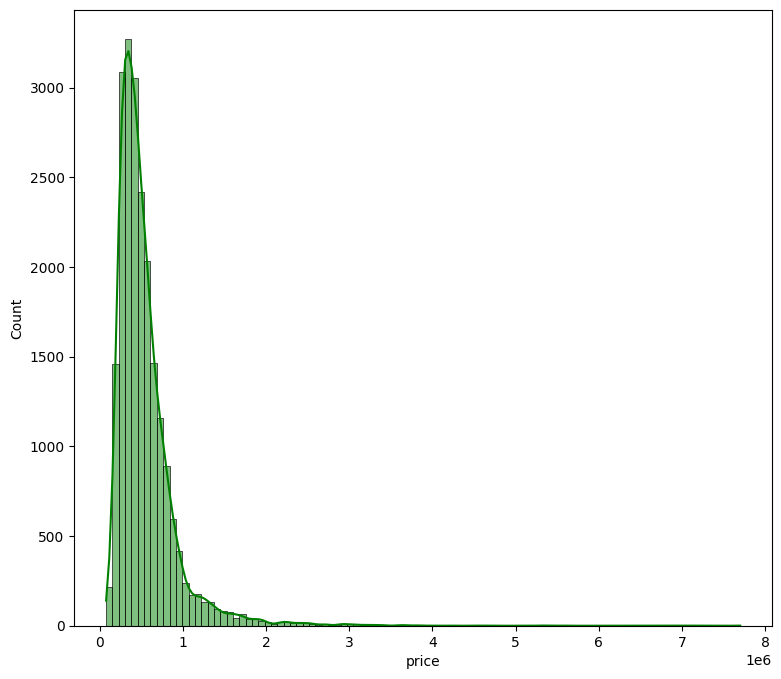

In [137]:
print(df["price"].describe())
plt.figure(figsize=(9, 8))
sns.histplot(df["price"], color="g", bins=100, kde=True)
plt.show()

**Chart type:** Histogram.

**Relationship:** Distribution

**Question this chart answers:** What does the distribution of King County home sale prices look like?

**Insight:** Prices are strongly right-skewed, with a long tail of expensive homes stretching well past $1M. Most sales cluster in the lower-to-mid price range, so the median is a more representative “typical price” than the mean for this market.

---

## Numerical data distribution

List every distinct dtype present in the dataframe, as a quick sanity check before splitting numeric from non-numeric columns.

In [138]:
list(set(df.dtypes.tolist()))

[dtype('int64'), dtype('<M8[us]'), dtype('float64')]

---

Keep only numeric columns (float64/int64) for correlation and distribution analysis below. This drops the datetime `date` column, which isn't meaningful in a numeric correlation matrix.

In [139]:
df_num = df.select_dtypes(include=["float64", "int64"])
df_num.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,221900.000,3.000,1.000,1180.000,5650.000,1.000,NaN,0.000,3,7,1180.000,0.000,1955,0.000,98178,47.511,-122.257,1340.000,5650.000
1,538000.000,3.000,2.250,2570.000,7242.000,2.000,0.000,0.000,3,7,2170.000,400.000,1951,19910.000,98125,47.721,-122.319,1690.000,7639.000
2,180000.000,2.000,1.000,770.000,10000.000,1.000,0.000,0.000,3,6,770.000,0.000,1933,NaN,98028,47.738,-122.233,2720.000,8062.000
3,604000.000,4.000,3.000,1960.000,5000.000,1.000,0.000,0.000,5,7,1050.000,910.000,1965,0.000,98136,47.521,-122.393,1360.000,5000.000
4,510000.000,3.000,2.000,1680.000,8080.000,1.000,0.000,0.000,3,8,1680.000,0.000,1987,0.000,98074,47.617,-122.045,1800.000,7503.000


---

Now lets plot a histogram for every numeric column at once, in a 16x20-inch grid, so the shape of each feature's distribution can be scanned quickly.

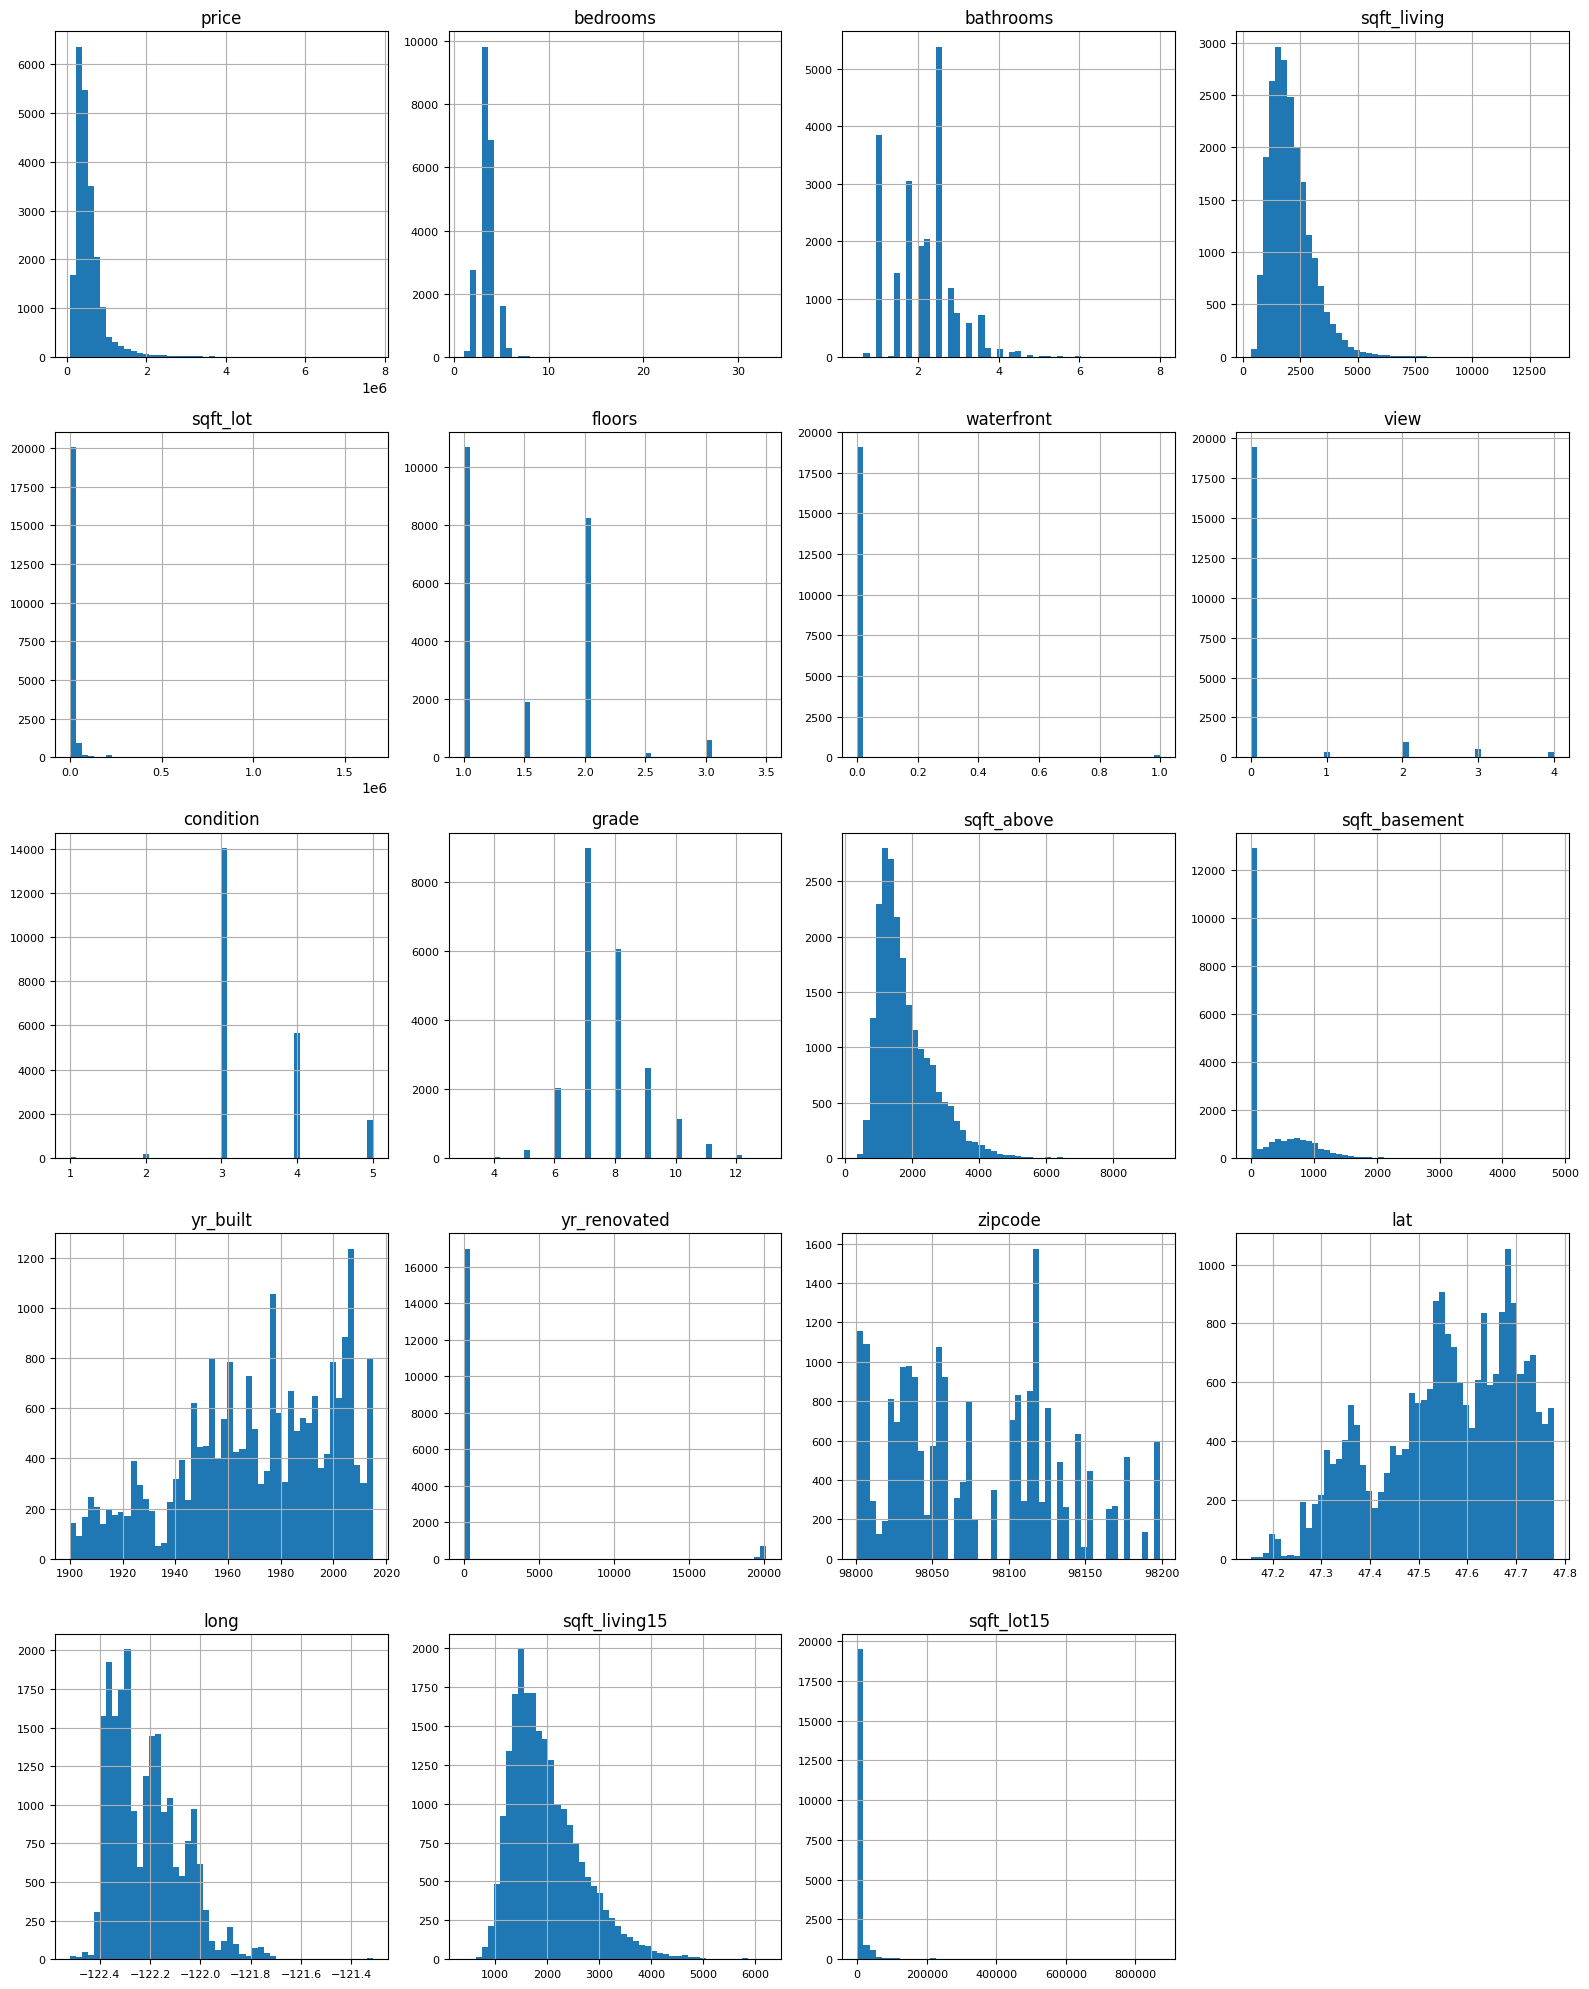

In [140]:
df_num.hist(figsize=(16, 20), bins=50, xlabelsize=8, ylabelsize=8)
plt.tight_layout()

**Chart type:** Grid of histograms — one per numeric column.

**Relationship:** Distribution
**Question this chart answers:** How is each numeric feature individually distributed, and which ones share price's right-skewed shape?

**Insight:** `sqft_living`, `sqft_above`, and `sqft_living15` all show the same right-skewed shape as price, hinting they may be strong linear predictors. 

Several columns (`waterfront`, `view`, `sqft_basement`, `yr_renovated`) are heavily zero-inflated — a large spike at 0 representing “absence of the feature” rather than a true measured value.

---

### Correlation

Now find which features are strongly correlated with `price`, stored in `golden_features_list`. Reuse `df_num` for this.

Note: `price` is the **first** column of `df_num`, so we drop it by name instead of slicing by position.

In [141]:
df_num_corr = df_num.corr()["price"].drop("price")
golden_features_list = df_num_corr[abs(df_num_corr) > 0.5].sort_values(ascending=False)
print(
    "There is {} strongly correlated values with price:\n{}".format(
        len(golden_features_list), golden_features_list
    )
)

There is 5 strongly correlated values with price:
sqft_living     0.702
grade           0.668
sqft_above      0.605
sqft_living15   0.585
bathrooms       0.526
Name: price, dtype: float64


This list is incomplete since correlation is affected by outliers and zero-inflated features. 

Let's plot the numerical features against `price` first, then repeat the correlation check after removing zero values from features where 0 likely means "absence" (`sqft_basement`, `waterfront`, `view`, `yr_renovated`).

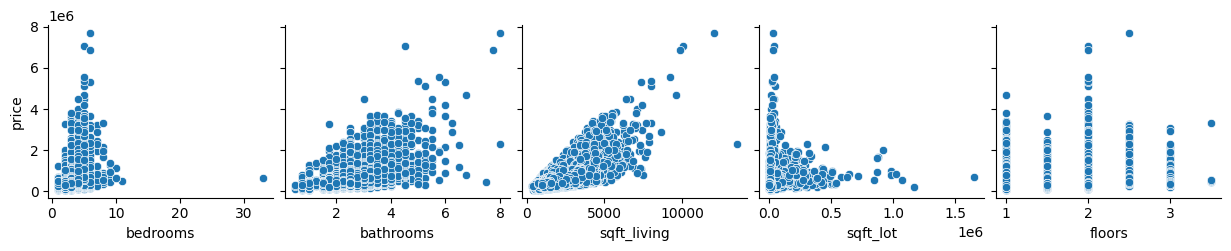

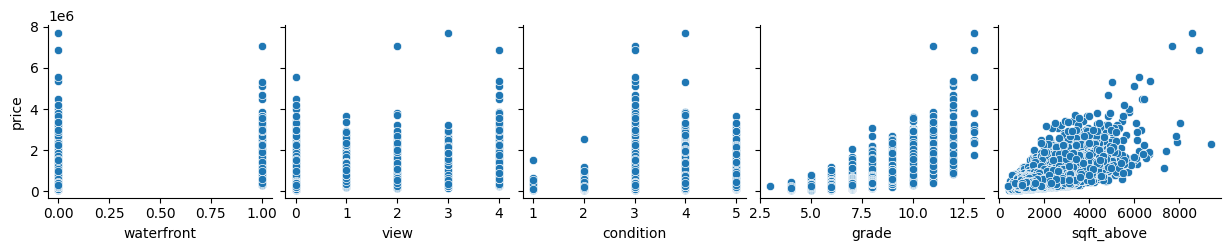

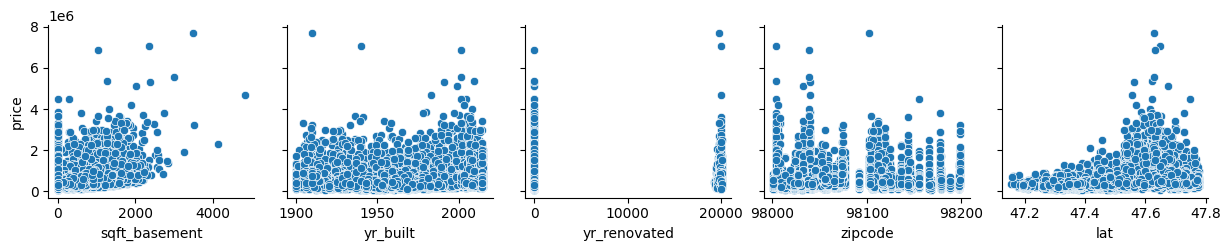

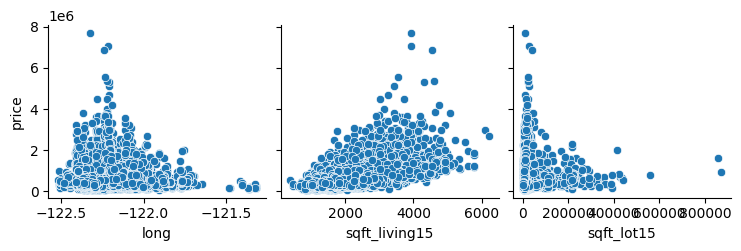

In [142]:
feature_cols = [c for c in df_num.columns if c != "price"]
for i in range(0, len(feature_cols), 5):
    sns.pairplot(data=df_num, x_vars=feature_cols[i : i + 5], y_vars=["price"])

**Chart type:** Grid of scatter plots — one per feature, feature vs. `price`.

**Relationship:** Correlation

**Question this chart answers:** Does each individual feature show a visible relationship with price, and are any features distorted by “absence” values sitting at zero?

**Insight:** Several features (`sqft_basement`, `waterfront`, `view`, `yr_renovated`) show a dense cluster of points at x = 0, representing homes without that feature rather than a true zero measurement. Left untreated, this understates how correlated those features really are with price.

---

Let's remove the zero rows and recheck correlation, one feature at a time.

In [143]:
individual_features_df = []
for col in feature_cols:
    if col == "waterfront":
        # binary flag, not a zero-inflated continuous measure — dropping its
        # "0" rows leaves a constant column, so correlation is undefined (NaN)
        continue
    tmp_df = df_num[[col, "price"]]
    tmp_df = tmp_df[tmp_df[col] != 0]
    individual_features_df.append(tmp_df)

# .iloc[0] instead of [0]: current pandas no longer allows positional
# lookup on a Series with a string index via plain [] indexing.
all_correlations = {
    feature.columns[0]: feature.corr()["price"].iloc[0]
    for feature in individual_features_df
}
all_correlations = sorted(all_correlations.items(), key=operator.itemgetter(1))
for key, value in all_correlations:
    print("{:>15}: {:>15}".format(key, value))

        zipcode: -0.05340243437756416
           long: 0.0220365086712475
      condition: 0.03605637548609444
       yr_built: 0.05395333346519124
     sqft_lot15: 0.0828449311749645
       sqft_lot: 0.0898762209908384
   yr_renovated: 0.1254991169134366
         floors: 0.25680353700802033
           view: 0.30154010660556757
            lat: 0.3066923142476342
       bedrooms: 0.30878747195653233
  sqft_basement: 0.4083533738156925
      bathrooms: 0.5259056214531991
  sqft_living15: 0.5852412017040635
     sqft_above: 0.6053679437051771
          grade: 0.6679507713876426
    sqft_living: 0.7019173021377558


---

With zero-inflated rows removed, here's the updated `golden_features_list` keeping only features with |correlation| >= 0.5.

In [144]:
golden_features_list = [key for key, value in all_correlations if abs(value) >= 0.5]
print(
    "There is {} strongly correlated values with price:\n{}".format(
        len(golden_features_list), golden_features_list
    )
)

There is 5 strongly correlated values with price:
['bathrooms', 'sqft_living15', 'sqft_above', 'grade', 'sqft_living']


---

### Conclusion so far

Correlation analysis on the numerical features points to `sqft_living`, `grade`, `sqft_above`, `sqft_living15`, `bathrooms`, and similar size/quality measures as the strongest single predictors of `price` unsurprisingly, but useful to confirm before building William Rodriguez's specific recommendations on top of it.

---

## Feature to feature relationship

Plotting every numerical feature against every other would be unreadable so, let's create a correlation heatmap restricted to feature pairs, excluding `price` (already examined above).

Only annotate cells where the correlation is reasonably strong (>= 0.5 or <= -0.4), so the heatmap isn't cluttered with weak relationships.

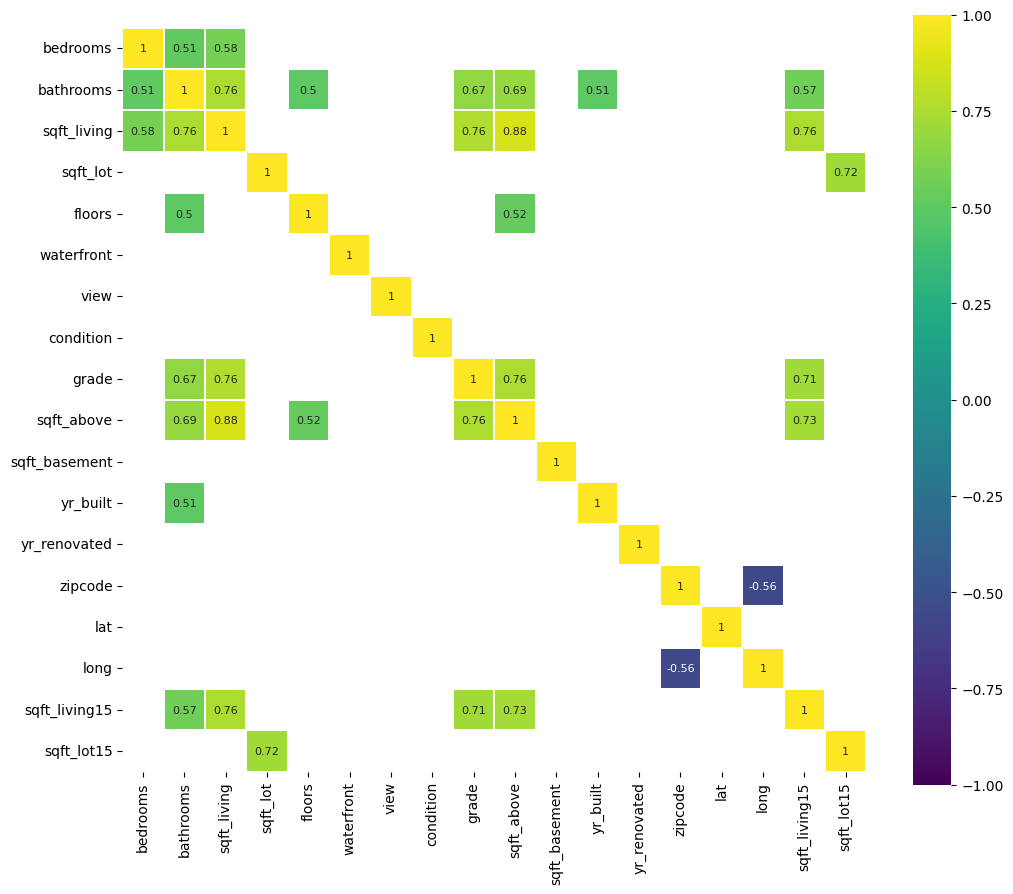

In [145]:
corr = df_num.drop(columns=["price"]).corr()
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr[(corr >= 0.5) | (corr <= -0.4)],
    cmap="viridis",
    vmax=1.0,
    vmin=-1.0,
    linewidths=0.1,
    annot=True,
    annot_kws={"size": 8},
    square=True,
)
plt.show()

**Chart type:** Heatmap of pairwise correlation coefficients.

**Relationship:** Correlation

**Question this chart answers:** Which pairs of features move together, independent of their individual relationship to price?

**Insight:** `sqft_living` correlates strongly with `sqft_above`, `grade`, `bathrooms`, and `sqft_living15` — these size/quality measures move together rather than providing fully independent information about price.

`lat`/`zipcode` relationships here are the geographic angle worth digging into separately for William Rodriguez's city/country question, since raw correlation won't capture that non-linear, location-based effect well.

---

## Q -> Q (Quantitative to Quantitative relationship)

Look at how the strongest numeric predictors relate to `price` individually, with a fitted regression line.

In [146]:
features_to_analyse = golden_features_list + ["price"]
features_to_analyse

['bathrooms', 'sqft_living15', 'sqft_above', 'grade', 'sqft_living', 'price']

Create a scatter plot + fitted regression line per golden feature, arranged in a grid with 3 columns 

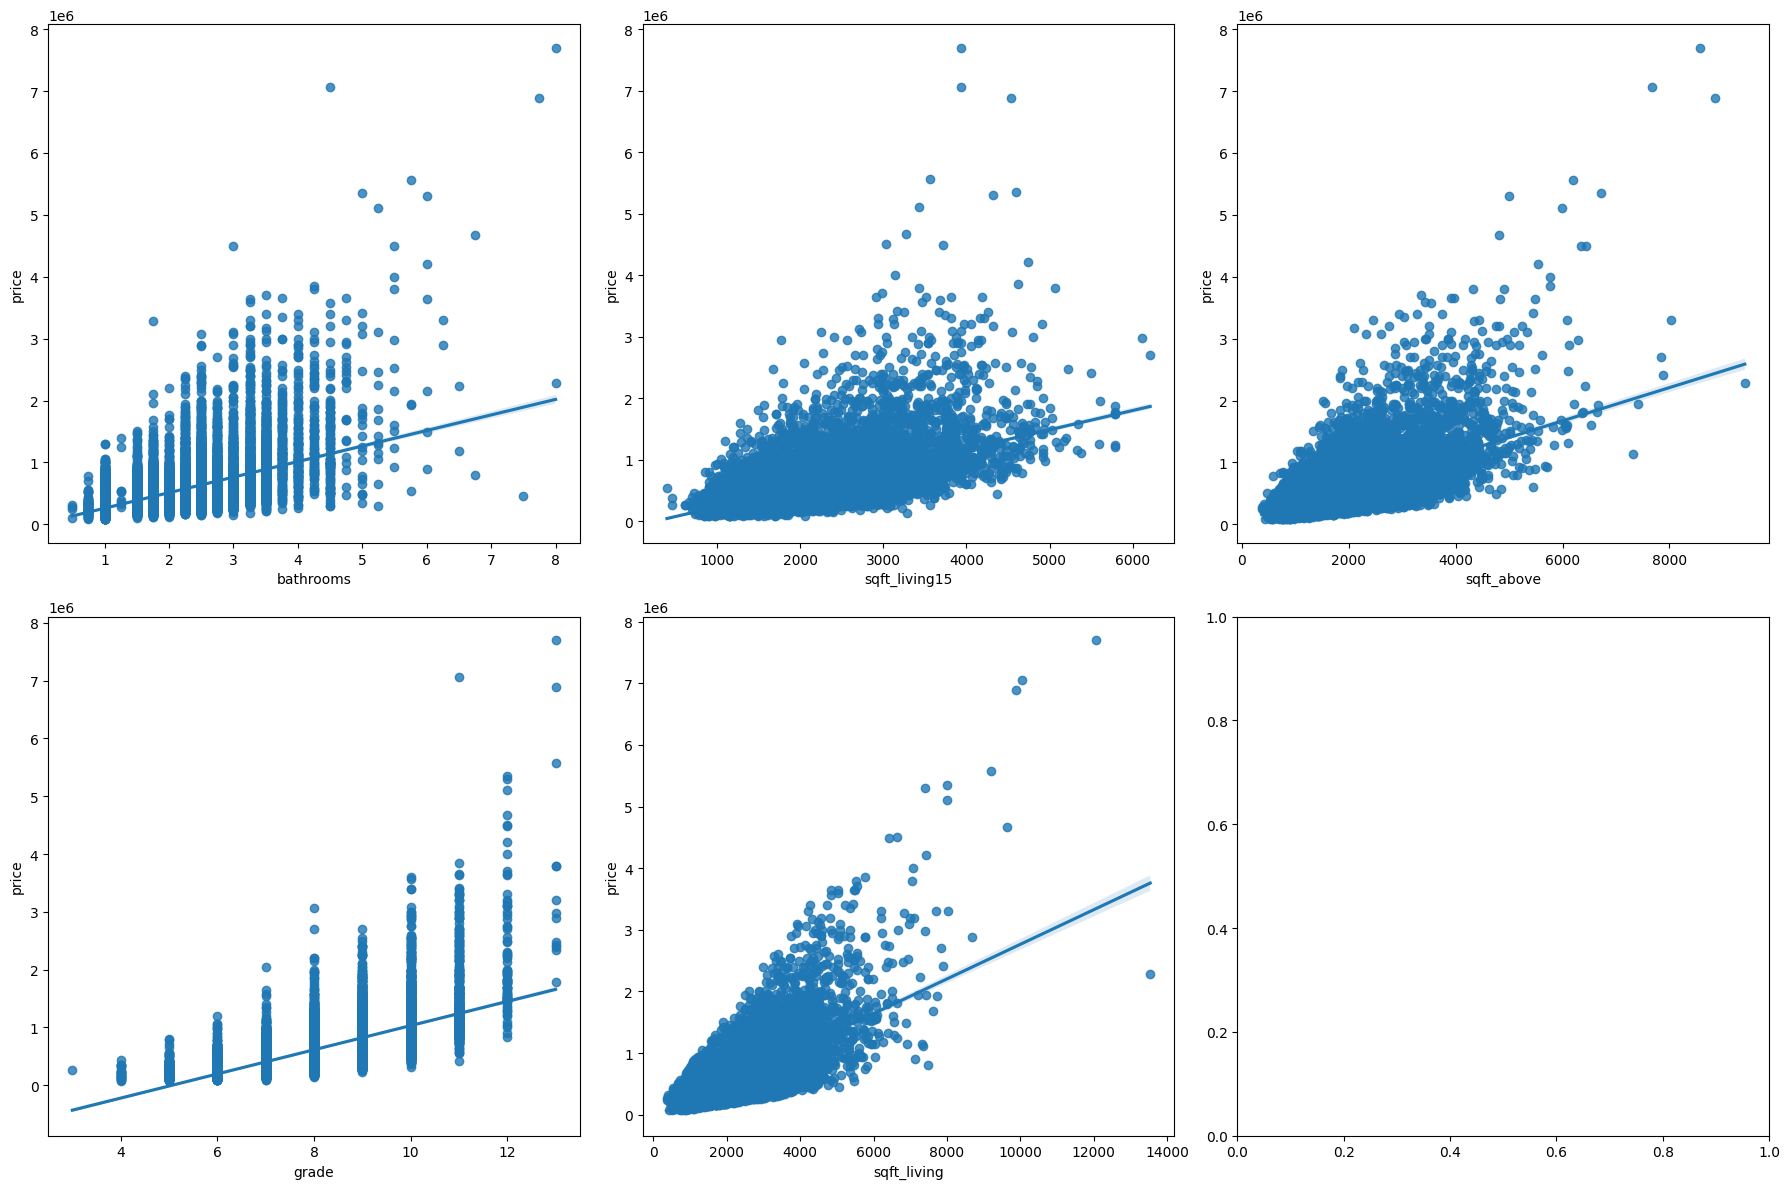

In [147]:
fig, axes = plt.subplots(round(len(features_to_analyse) / 3), 3, figsize=(18, 12))

for i, ax in enumerate(fig.axes):
    if i < len(features_to_analyse) - 1:
        sns.regplot(x=features_to_analyse[i], y="price", data=df[features_to_analyse], ax=ax)

plt.tight_layout()

**Chart type:** Grid of scatter plots with a fitted linear regression line

**Relationship:** Correlation

**Question this chart answers:** Does each of the top correlated features (bathrooms, sqft_living15, sqft_above, grade, sqft_living) show a genuinely linear relationship with price, or just a numeric correlation coefficient?

**Insight:** All five golden features show a clear upward linear trend against price, confirming the correlation values are backed by a real visual relationship rather than being driven by a handful of outliers.

---

## C -> Q (Categorical to Quantitative relationship)

Almost everything here is numeric by nature. The closest categorical stand-ins are `zipcode`, `condition`, `grade`, `waterfront`, and `view` (all effectively categories even though they're stored as numbers), plus the `is_city`/`is_country` flags built in this notebook's segmentation cell for William Rodriguez's geographic question.

In [148]:
# Reference point: downtown Seattle (used to measure how central each sale is).
SEATTLE_DOWNTOWN = (47.6062, -122.3321)

def haversine_km(lat1, lon1, lat2, lon2):
    # Great-circle distance (in km) between two lat/long points on Earth's
    # surface, using the haversine formula.
    r = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

# Distance from each sale to downtown Seattle, in kilometers
df["dist_to_downtown_km"] = haversine_km(df["lat"], df["long"], *SEATTLE_DOWNTOWN)

# "City" = closest 25% of sales to downtown (by distance)
df["is_city"] = df["dist_to_downtown_km"] <= df["dist_to_downtown_km"].quantile(0.25)

# "Country" = largest 25% of lots county-wide (by sqft_lot)
df["is_country"] = df["sqft_lot"] >= df["sqft_lot"].quantile(0.75)

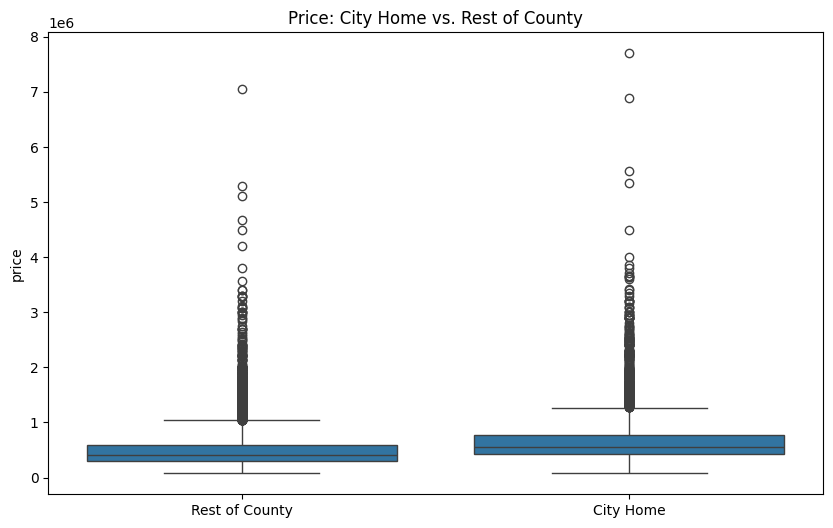

In [149]:
# Compare price distributions for "city" homes vs. the rest of the county.
# Note: this splits only on is_city, not is_country - "the rest of the
# county" is not the same group as "country homes" (see the note at the
# top of this section), so the x-axis labels say "Rest of County" rather
# than "Country Home."
plt.figure(figsize=(10, 6))
ax = sns.boxplot(x="is_city", y="price", data=df)
plt.setp(ax.artists, alpha=0.5, linewidth=2, edgecolor="k")
ax.set_xticklabels(["Rest of County", "City Home"])
ax.set_xlabel("")
plt.title("Price: City Home vs. Rest of County")
plt.show()

**Chart type:** Boxplot — price distribution split by group.

**Relationship:** Comparison 

**Question this chart answers:** Do homes closer to downtown Seattle (“city”) sell for different prices than the rest of the county?

**Insight:** City-classified homes have a visibly higher median price and a wider spread than the rest of the county, directly supporting the geographic research question.

---

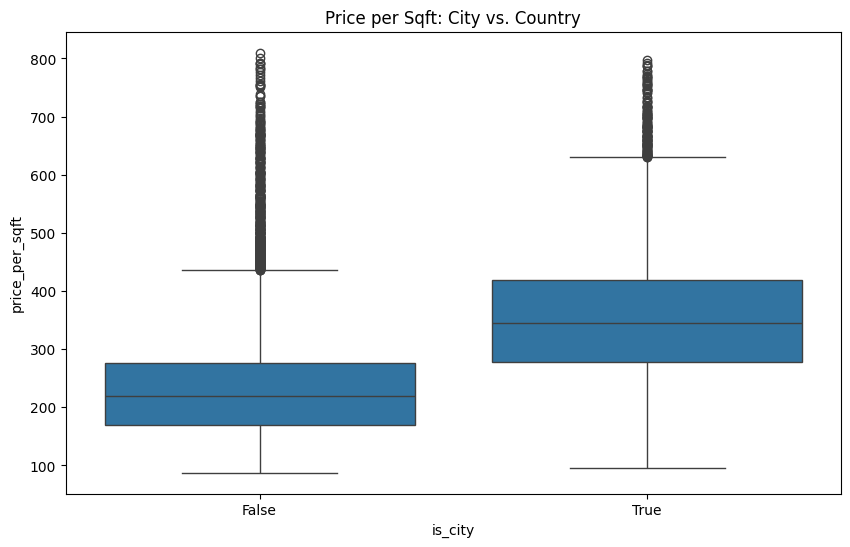

In [ ]:
# Same comparison, but on price per square foot instead of raw price,
# to see if the location premium holds once home size is controlled for.
df["price_per_sqft"] = df["price"] / df["sqft_living"]

plt.figure(figsize=(10, 6))
ax = sns.boxplot(x="is_city", y="price_per_sqft", data=df)
plt.setp(ax.artists, alpha=0.5, linewidth=2, edgecolor="k")
ax.set_xticklabels(["Rest of County", "City Home"])
ax.set_xlabel("")
plt.title("Price per Sqft: City Home vs. Rest of County")
plt.show()

**Chart type:** Boxplot — price-per-sqft distribution split by group

**Relationship:** Comparison

**Question this chart answers:** Once home size is controlled for, does location still command a premium?

**Insight:** City homes cost more per square foot of living space than the rest of the county, showing the location premium holds even after adjusting for size — it isn't just that city homes happen to be bigger.

---

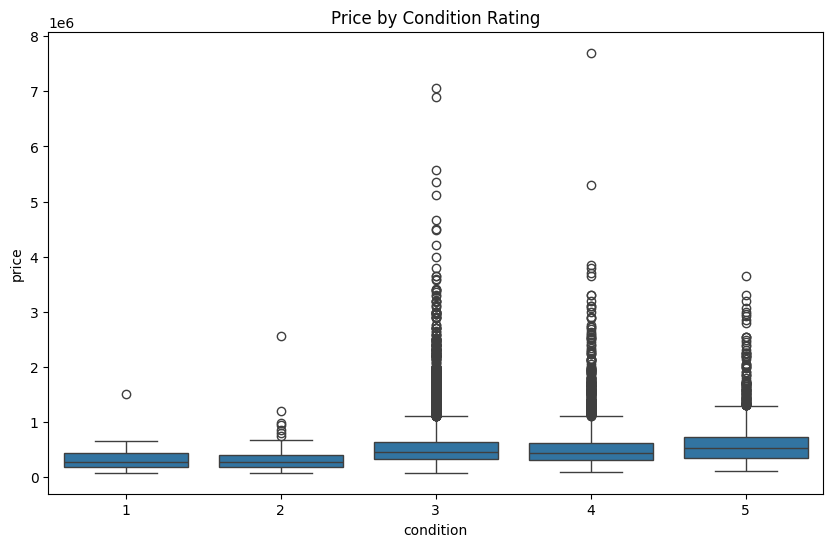

In [151]:
# Compare price distributions across the 5 condition ratings.
plt.figure(figsize=(10, 6))
ax = sns.boxplot(x="condition", y="price", data=df)
plt.setp(ax.artists, alpha=0.5, linewidth=2, edgecolor="k")
plt.title("Price by Condition Rating")
plt.show()

**Chart type:** Boxplot — price distribution split by condition rating

**Relationship:** Comparison

**Question this chart answers:** Does a home's condition rating relate to its sale price?

**Insight:** Median price doesn't rise cleanly as condition improves — condition alone is a weaker, noisier price signal than size (sqft_living) or quality (grade).

---

William Rodriguez's household is just 2 people, so check if he needs to pay a "size premium" for bedrooms a 2-person household doesn't actually need. 

First look at how many listings exist at each bedroom count.

bedrooms
1.000      196
2.000     2760
3.000     9824
4.000     6882
5.000     1601
6.000      272
7.000       38
8.000       13
9.000        6
10.000       3
11.000       1
33.000       1
Name: count, dtype: int64


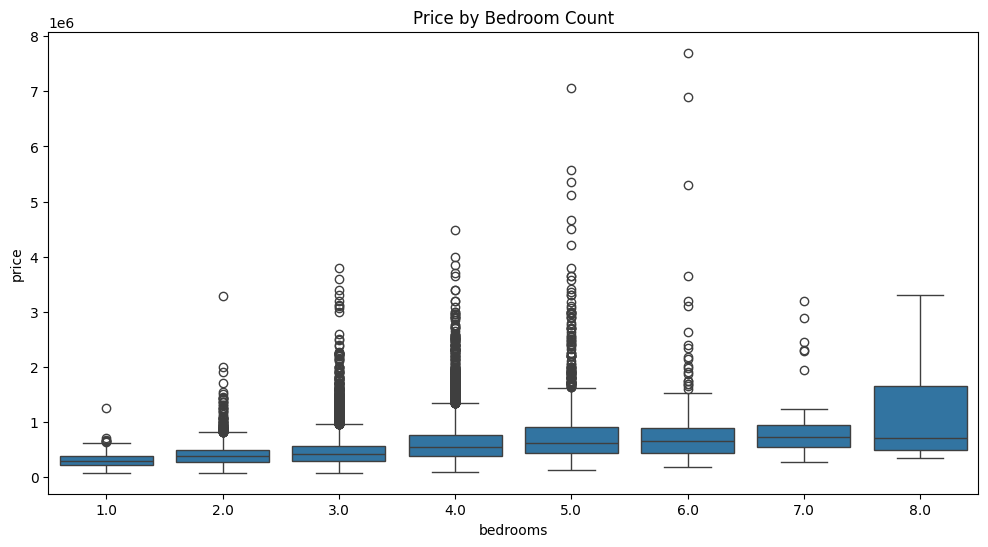


1-3 bedroom homes: median price $400,000, 12,780 listings (59.2% of the market)
4+ bedroom homes:  median price $565,000, 8,817 listings (40.8% of the market)
4+ bedroom premium over 1-3 bedroom: 41.2%


In [152]:
print(df["bedrooms"].value_counts().sort_index())

plt.figure(figsize=(12, 6))
ax = sns.boxplot(x="bedrooms", y="price", data=df[df["bedrooms"] <= 8])
plt.setp(ax.artists, alpha=0.5, linewidth=2, edgecolor="k")
plt.title("Price by Bedroom Count")
plt.show()

# Quantify the size premium directly: compare 1-3 bedroom homes (plenty of
# room for a 2-person household) against 4+ bedroom homes.
small_hh = df[df["bedrooms"].isin([1, 2, 3])]
large_hh = df[df["bedrooms"] >= 4]
premium_pct = (large_hh["price"].median() - small_hh["price"].median()) / small_hh["price"].median() * 100

print(f"\n1-3 bedroom homes: median price ${small_hh['price'].median():,.0f}, "
      f"{len(small_hh):,} listings ({len(small_hh) / len(df) * 100:.1f}% of the market)")
print(f"4+ bedroom homes:  median price ${large_hh['price'].median():,.0f}, "
      f"{len(large_hh):,} listings ({len(large_hh) / len(df) * 100:.1f}% of the market)")
print(f"4+ bedroom premium over 1-3 bedroom: {premium_pct:.1f}%")

**Chart type:** Boxplot — price distribution split by bedroom count, followed by a direct median-price comparison between 1-3 bedroom and 4+ bedroom homes.

**Relationship:** Comparison

**Question this chart answers:** Does William Rodriguez, buying for a household of 2, need to pay a size premium for bedrooms he won't use?

**Insight:** Price rises steadily with bedroom count. 1-3 bedroom homes — comfortably enough for a 2-person household — make up 59.2% of the market at a median price of $400,000, versus $565,000 for 4+ bedroom homes, a 41.2% premium. William Rodriguez can target the majority of available listings (which also supports the "fast" requirement on the city home) without paying for space he doesn't need. Note: one listing shows "33 bedrooms" on a ~1,620 sqft home — almost certainly a data-entry error (likely meant to be 3) — and is excluded from this chart.

---

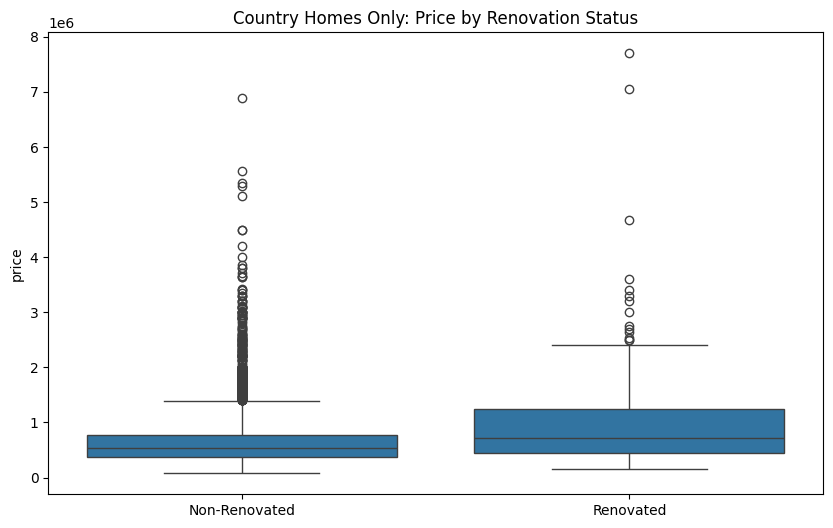

In [153]:
# Restrict to "country" homes only, then compare renovated vs. non-renovated
# price within that subset (rather than across the whole dataset).
country_df = df[df["is_country"]]
renovated_country = country_df["yr_renovated"].fillna(0) > 0

plt.figure(figsize=(10, 6))
ax = sns.boxplot(x=renovated_country, y=country_df["price"])
plt.setp(ax.artists, alpha=0.5, linewidth=2, edgecolor="k")
ax.set_xticklabels(["Non-Renovated", "Renovated"])
ax.set_xlabel("")
plt.title("Country Homes Only: Price by Renovation Status")
plt.show()

**Chart type:** Boxplot — price distribution split by renovation status, filtered to “country” homes only

**Relationship:** Comparison

**Question this chart answers:** Among large-lot (“country”) homes specifically, does renovation status affect price?

**Insight:** Renovated country homes have a noticeably higher median price than non-renovated ones. That's good news for William Rodriguez, since he prefers non-renovated homes at the lower price point.

---

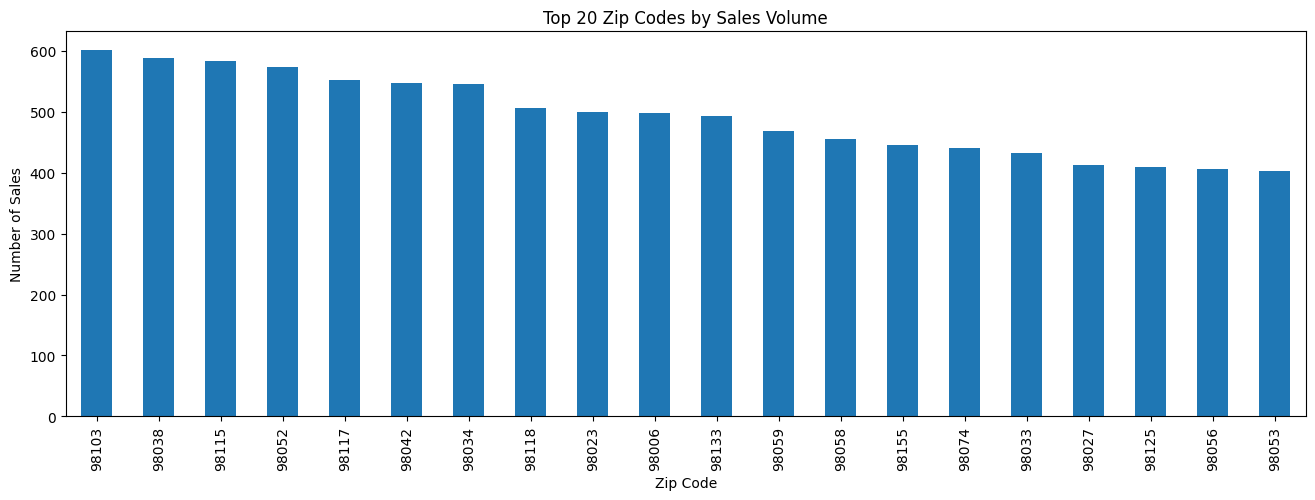

In [154]:
# Count sales per zip code and plot the 20 zip codes with the most activity.
plt.figure(figsize=(16, 5))
df["zipcode"].value_counts().head(20).plot(kind="bar")
plt.title("Top 20 Zip Codes by Sales Volume")
plt.xlabel("Zip Code")
plt.ylabel("Number of Sales")
plt.show()

**Chart type:** Bar chart — sales count per zip code, top 20

**Relationship:** Comparison

**Question this chart answers:** Which zip codes have the most sales activity (highest turnover)?

**Insight:** A handful of zip codes account for disproportionately more transactions than the rest — these are the best candidates for a “fast” city-home search, since more listings cycle through them.

---

Zip-code-level view supporting the specific zip recommendations made for William Rodriguez:
Which zips are the best "city" candidates (close to downtown, high turnover, low large-lot share) and which are the best "country" candidates (far from downtown, mostly large-lot). 

Aggregate to one row per zip code, keeping only zips with at least 50 sales so a handful of outlier listings don't distort the picture.

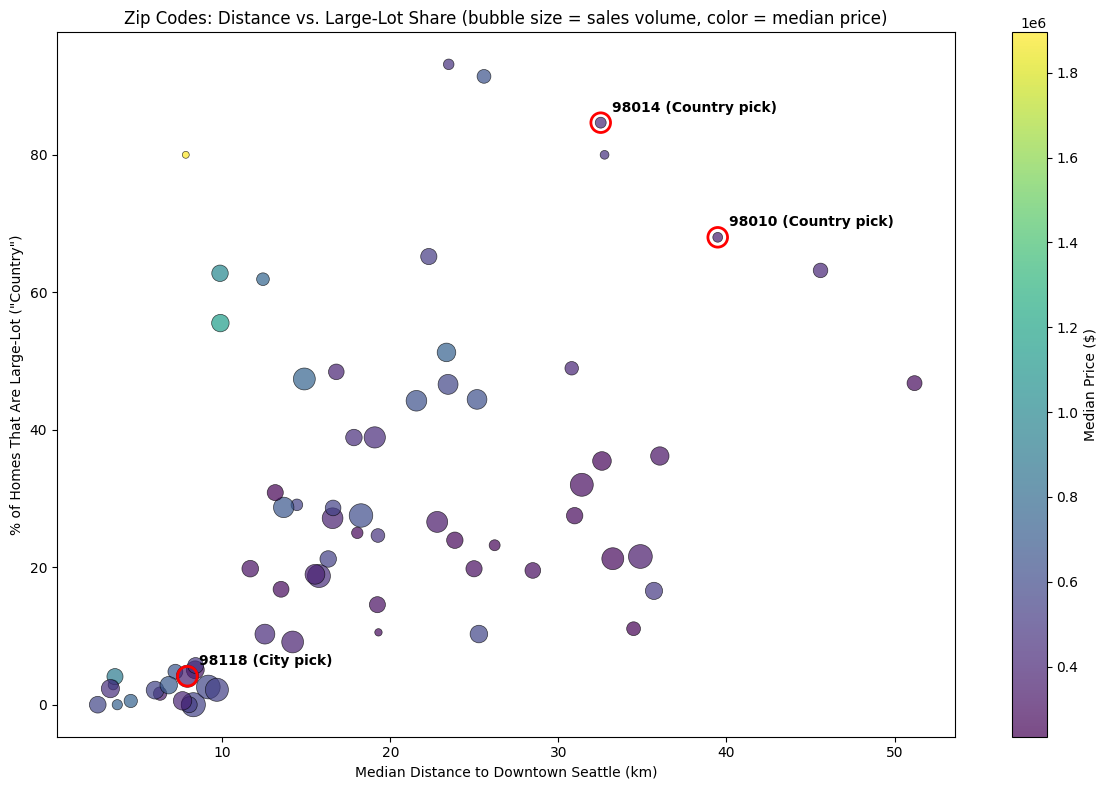

In [155]:
zip_stats = (
    df.groupby("zipcode")
    .agg(
        median_price=("price", "median"),
        dist_km=("dist_to_downtown_km", "median"),
        pct_large_lot=("is_country", "mean"),
        sales=("price", "count"),
    )
    .reset_index()
)
zip_stats["pct_large_lot"] = zip_stats["pct_large_lot"] * 100
zip_stats = zip_stats[zip_stats["sales"] >= 50]

# The specific zips recommended in the presentation deck: 98118 for the
# city home, 98010 and 98014 for the country home.
highlight_zips = {98118: "City pick", 98010: "Country pick", 98014: "Country pick"}

plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    zip_stats["dist_km"],
    zip_stats["pct_large_lot"],
    s=zip_stats["sales"] / 2,  # bubble size = sales volume (turnover)
    c=zip_stats["median_price"],
    cmap="viridis",
    alpha=0.7,
    edgecolors="k",
    linewidths=0.5,
)
plt.colorbar(scatter, label="Median Price ($)")

# Circle and label the three recommended zips so they stand out against
# the rest of the county.
for z, label in highlight_zips.items():
    row = zip_stats[zip_stats["zipcode"] == z]
    if not row.empty:
        x, y = row["dist_km"].values[0], row["pct_large_lot"].values[0]
        plt.scatter(x, y, s=200, facecolors="none", edgecolors="red", linewidths=2)
        plt.annotate(
            f"{z} ({label})", (x, y), xytext=(8, 8),
            textcoords="offset points", fontsize=10, fontweight="bold",
        )

plt.xlabel("Median Distance to Downtown Seattle (km)")
plt.ylabel('% of Homes That Are Large-Lot ("Country")')
plt.title("Zip Codes: Distance vs. Large-Lot Share (bubble size = sales volume, color = median price)")
plt.tight_layout()
plt.show()

**Chart type:** Bubble scatter plot — one point per zip code (bubble size = sales volume, color = median price), with the three recommended zips circled and labeled.

**Relationship:** Correlation

**Question this chart answers:** Which specific zip codes actually fit William Rodriguez's "city" (central, high-turnover) and "country" (large-lot, low-density) criteria, and how do the recommended zips (98118, 98010, 98014) compare to the rest of the county?

**Insight:** Large-lot share generally rises with distance from downtown, but not uniformly — a few close-in zips are unusually large-lot outliers with very low sales counts, and some far-out zips are still mostly small-lot. Zip 98118 sits in the close-in, high-turnover, low-large-lot cluster at an affordable median price ($367,500), making it a genuine "city" pick rather than just a high-volume one. Zips 98010 and 98014 sit in the far-out, high-large-lot cluster (68% and 85% large-lot respectively) at affordable medians ($360,000 and $415,000), confirming they're genuine "country" picks and not just distant zip codes.

---

City homes:
       median_price  num_sales
date                         
1       550000.000        223
2       554000.000        269
3       588750.000        464
4       577500.000        577
5       565000.000        665
6       559500.000        556
7       565000.000        546
8       543000.000        446
9       542000.000        443
10      550000.000        496
11      537500.000        366
12      550000.000        349 

Country homes:
       median_price  num_sales
date                         
1       524112.500        258
2       519500.000        297
3       530000.000        443
4       575000.000        537
5       540000.000        604
6       552000.000        594
7       550000.000        579
8       493725.000        512
9       540000.000        434
10      535000.000        440
11      525000.000        335
12      515000.000        367


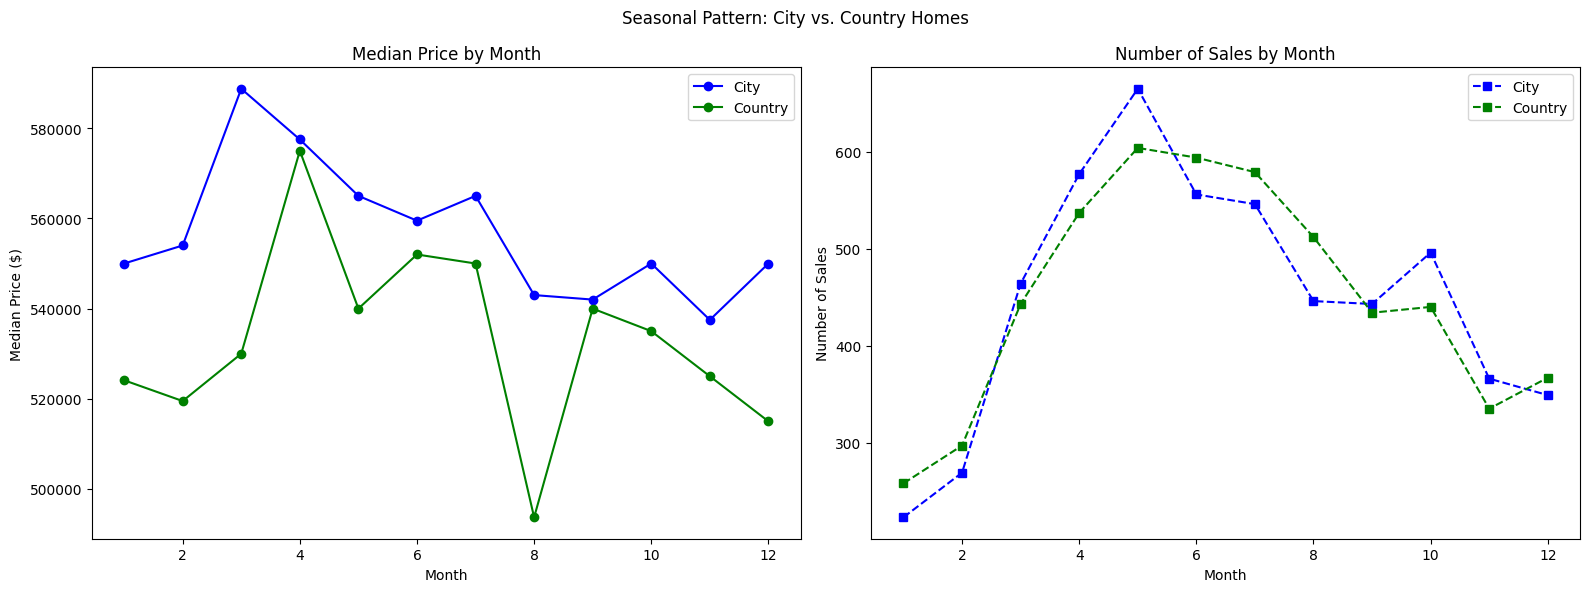

In [156]:
# Group by calendar month (ignoring year), split by is_city / is_country,
# to check whether the two property types dip at different times of year
# rather than assuming one county-wide seasonal pattern applies to both.
monthly_all = df.groupby(df["date"].dt.month)["price"].agg(["median", "count"])
monthly_city = df[df["is_city"]].groupby(df["date"].dt.month)["price"].agg(["median", "count"])
monthly_country = df[df["is_country"]].groupby(df["date"].dt.month)["price"].agg(["median", "count"])

monthly_all.columns = ["median_price", "num_sales"]
monthly_city.columns = ["median_price", "num_sales"]
monthly_country.columns = ["median_price", "num_sales"]

print("City homes:\n", monthly_city, "\n")
print("Country homes:\n", monthly_country)

# Two side-by-side panels: median price by month (left) and sales volume by
# month (right), each with a line for city homes and a line for country
# homes, so the two groups' seasonal patterns can be compared directly.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

monthly_city["median_price"].plot(ax=ax1, color="b", marker="o", label="City")
monthly_country["median_price"].plot(ax=ax1, color="g", marker="o", label="Country")
ax1.set_title("Median Price by Month")
ax1.set_xlabel("Month")
ax1.set_ylabel("Median Price ($)")
ax1.legend()

monthly_city["num_sales"].plot(ax=ax2, color="b", marker="s", linestyle="--", label="City")
monthly_country["num_sales"].plot(ax=ax2, color="g", marker="s", linestyle="--", label="Country")
ax2.set_title("Number of Sales by Month")
ax2.set_xlabel("Month")
ax2.set_ylabel("Number of Sales")
ax2.legend()

plt.suptitle("Seasonal Pattern: City vs. Country Homes")
plt.tight_layout()
plt.show()

**Chart type:** Two side-by-side line charts — median price by month and sales count by month, each split into a "city" line and a "country" line (`DataFrame.plot`, grouped by `is_city`/`is_country`).

**Relationship:** Trend / Change over time

**Question this chart answers:** Does the "best time to buy" differ between city homes and country homes, rather than a single county-wide seasonal pattern applying to both?

**Insight:** The two groups dip at different times. 

City homes hit their lowest median price in **November** ($537,500) and peak in March ($588,750). 

Country homes hit their lowest median price in **August** ($493,725) and peak in April ($575,000). 

---

### Conclusion

Size and quality features (`sqft_living`, `grade`, `sqft_above`, `sqft_living15`, `bathrooms`) are the strongest single numeric predictors of `price`, and location (`zipcode`/distance to downtown) matters in a way plain correlation doesn't capture well — exactly the geographic angle William Rodriguez's two-house search depends on.

Four findings carry directly into his search:

- **Geographic:** city homes carry a per-square-foot premium over the rest of the county; country ("large-lot") homes cost less per square foot even though they don't sell for less overall.
- **Renovation:** among country homes, renovated listings carry a real price premium over non-renovated ones — good news given William Rodriguez prefers non-renovated stock.
- **Seasonality:** timing differs by property type. Country homes are cheapest in August; city homes are cheapest in November — a single county-wide "best month" doesn't hold for both searches at once.
- **Household size:** at 2 people, William Rodriguez doesn't need 4+ bedrooms — 1-3 bedroom homes cover the majority of the market at a meaningfully lower price.

These findings are the basis for the insights and recommendations in the README and the presentation deck.